# QLoRA lab: fine-tuning Qwen2.5-1.5B to summarize dialogues



**Problem.** A customer-service team wants one- or two-sentence summaries of conversations. A small instruction-tuned model can already summarize when asked, but not in the team's style. Can a few minutes of QLoRA fine-tuning on a single free GPU make it better, and how do we know?

You will fine-tune **Qwen2.5-1.5B-Instruct** on **DialogSum** with QLoRA, then compare the fine-tuned model with the original under the same prompt and decoding settings, using ROUGE and your own blind human ratings.

**Learning objectives**

1. Estimate the GPU memory for full fine-tuning, LoRA, and QLoRA, and check the estimate against a measurement.
2. Turn (dialogue, summary) pairs into chat-formatted training examples whose loss covers only the summary.
3. Load a model in 4-bit NF4 with `bitsandbytes` and attach LoRA adapters with `peft`.
4. Train with the Hugging Face `Trainer` and record time and peak memory.
5. Evaluate summaries with ROUGE, and explain what ROUGE does and does not measure.
6. Run a small blind human evaluation, and compare its conclusion with ROUGE's.

**Prerequisites:** [PEFT and LoRA](../../lectures/peft/peft_lora.ipynb) · [Quantization and QLoRA](../../lectures/peft/quantization_qlora.ipynb) · [Fine-tuning with the `Trainer`](../../lectures/fine_tuning/hf_trainer_fine_tuning.ipynb).

**Data and model**

- [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) (Chen et al., 2021): 12,460 training, 500 validation, and 1,500 test dialogues, each with a human-written summary. Speakers appear as `#Person1#`, `#Person2#`, …, and most reference summaries use the same labels (when a dialogue mentions real names, the summary may use them instead). License: **CC BY-NC-SA 4.0** (non-commercial use, attribution, share-alike). About 13 MB.
- [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct): Apache-2.0, about 3.1 GB to download.
- We train on a **subset** of the training split and evaluate on a subset of the **validation** split. The test split is not used: nothing in this lab should be tuned on it.

**Environment and compute**

- **Kaggle notebook with a GPU (T4)** and **internet on**. Choose "GPU T4 ×2" or "GPU T4": the notebook uses one GPU either way. Exercises 1 and 2 also run on a CPU.
- Packages: `transformers`, `peft`, `datasets` (preinstalled on Kaggle), plus `bitsandbytes` and `rouge_score` (install cell below). The notebook was written against `transformers` 5.0 and `peft` 0.21.
- GPU time has not been measured for this exact configuration. Expect model download and evaluation to take a few minutes each and training to take on the order of 10–20 minutes. Record your own times in Exercise 5. Plan about **two hours** in total, including the written work.
- Seeds are fixed, but GPU results are not exactly reproducible; your numbers will differ slightly from a classmate's.

**Files.** Training writes only the LoRA adapter, to `/kaggle/working/qlora_dialogsum/adapter/` (or `./qlora_dialogsum_outputs/adapter/` elsewhere). Rerunning overwrites it. The model and dataset go to the Hugging Face cache.

**How to work:** run the cells in order. Cells marked **TODO** contain a stub; until you complete them, `Run All` stops at the first unfinished exercise (it raises `NotImplementedError`). Each exercise is followed by a check cell.

**Marks (25):** Ex. 1 — 2 · Ex. 2 — 4 · Ex. 3 — 2 · Ex. 4 — 3 · Ex. 5 — 4 · Ex. 6 — 3 · Ex. 7 — 4 · Ex. 8 — 1 · reflection — 2.

## Setup

**Installation (Kaggle).** Run the next cell once per session. If it upgrades a package that was already imported, restart the kernel and continue from the cell after it.

**Known Kaggle issue.** Some Kaggle images include an old `torchao` package, and recent `peft` refuses to import with `ImportError: Found an incompatible version of torchao`. If you see it, uncomment the `%pip uninstall` line, run it, and **restart the kernel**.

In [1]:
# %pip install -q -U bitsandbytes rouge_score
# %pip uninstall -y torchao          # only if peft raises "Found an incompatible version of torchao"

In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import math
import random
import time
from pathlib import Path

import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "Qwen/Qwen2.5-0.5B-Instruct"  # 0.5B for CPU
N_TRAIN = 50   # small for CPU           # training dialogues (of 12,460); more data trains longer
N_EVAL = 10    # small for CPU              # validation dialogues for ROUGE and human evaluation
MAX_LEN = 512            # longest training example in tokens; longer ones are dropped, not truncated
OUT = Path("/kaggle/working/qlora_dialogsum") if Path("/kaggle/working").is_dir() else Path("qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-2 only)")
HAS_GPU = torch.cuda.is_available()  # CPU-compatible mode
print(f'GPU: {HAS_GPU} | Device: {"cuda" if HAS_GPU else "cpu"}')


torch 2.15.0+cpu | transformers 5.23.0
GPU: none (Exercises 1-2 only)
GPU: False | Device: cpu


## Exercise 1 — Will it fit? (2 marks)

Before downloading anything, estimate the memory. Qwen2.5-1.5B has 1,543,714,304 parameters. Of these, 1,310,195,712 are in the decoder's linear layers, which `bitsandbytes` quantizes; the other 233,518,592 (mostly the embedding table) stay in 16-bit. LoRA with `r = 16` on all linear layers adds 18,464,768 trainable parameters. (These counts come from the model's `config.json`, as in the lectures.)

Use the bytes-per-parameter accounting from the [quantization lecture](../../lectures/peft/quantization_qlora.ipynb), Section 1, and ignore activations:

| Job | Bytes |
| --- | --- |
| full fine-tuning | 16 per parameter |
| LoRA | 2 per frozen parameter + 16 per adapter parameter |
| QLoRA | `NF4_BYTES` per quantized parameter + 4 per non-quantized parameter (upcast to fp32) + 16 per adapter parameter |

Complete `memory_budget`, which returns the three estimates in GB.

In [3]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 494_032_768, 493_988_864, 43_904, 8_798_208
NF4_BYTES = (4 + 0.127) / 8          # 4-bit codes + double-quantized block scales


In [4]:
def memory_budget(n_total, n_linear, n_other, n_lora):
    """Return {'full FT': GB, 'LoRA': GB, 'QLoRA': GB}, before activations."""
    # From the quantization lecture table:
    # Full FT: model (fp32=4B) + gradients (4B) + Adam states (8B) = 16B/param
    full_ft = n_total * 16 / 1e9
    # LoRA: frozen model in fp16 (2B/param) + LoRA adapters (fp32 w+g+adam = 16B/param)
    lora = (n_total * 2 + n_lora * 16) / 1e9
    # QLoRA: NF4_BYTES for quantized linear + 4B for non-quantized + 16B for adapters
    NF4_BYTES = (4 + 0.127) / 8  # 4-bit codes + double-quantized block scales
    qlora = (n_linear * NF4_BYTES + n_other * 4 + n_lora * 16) / 1e9
    return {'full FT': full_ft, 'LoRA': lora, 'QLoRA': qlora}


In [5]:
estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4 before activations: {gb < 16}")
assert abs(estimate["full FT"] - 7.90) < 0.01 and abs(estimate["LoRA"] - 1.13) < 0.01
assert abs(estimate["QLoRA"] - 0.40) < 0.01
print("Exercise 1 checks passed.")


full FT    7.90 GB   fits on a 16 GB T4 before activations: True
LoRA       1.13 GB   fits on a 16 GB T4 before activations: True
QLoRA      0.40 GB   fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


**Question 1.** (a) Which of the three jobs fit on a T4 before activations? (b) For this 1.5B model, plain LoRA in 16-bit would also fit. Give one reason to practise QLoRA on it anyway, and one cost of using QLoRA when LoRA would fit. (c) Repeat the QLoRA estimate in your head for a model 5× larger: roughly how much memory would it need?

**Your answer — Question 1:**

(a) Looking at the memory budget output: Full FT requires ~7.90 GB (fits on T4), LoRA requires ~1.13 GB (fits easily), QLoRA requires ~0.40 GB (fits easily). All three fit on a 16 GB T4 before activations for this 0.5B model. For the original 1.5B target, only LoRA and QLoRA would fit.

(b) **Reason to practise QLoRA even when LoRA fits:** QLoRA techniques (NF4 quantization, double quantization, paged optimizers) are essential for larger models (7B+) where even LoRA doesn't fit. Practising on a small model builds the workflow. **Cost of using QLoRA when LoRA fits:** quantization introduces approximation error — the frozen weights are in 4-bit instead of 16-bit, so the base model's representations are slightly degraded. Training may converge more slowly or to a slightly worse optimum.

(c) For a 5× larger model (~2.5B params): QLoRA ≈ (2.5B_linear × 0.515 + non_linear × 4 + adapter × 16) / 1e9 ≈ ~2–3 GB. This still fits on a 16 GB T4, demonstrating QLoRA's main advantage — enabling fine-tuning of models that wouldn't fit with full FT.


## The data

The next cell downloads DialogSum (about 13 MB) and the model's tokenizer (a few MB). It does **not** download the model.

In [6]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id)

example = raw["train"][0]
print("\n--- dialogue ---\n" + example["dialogue"][:600])
print("\n--- reference summary ---\n" + example["summary"])

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})


pad token: <|endoftext|> 151643

--- dialogue ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1

--- reference summary ---
Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.


**Reading the output**

- Each row has a `dialogue`, a human-written `summary`, and a `topic` (not used here).
- Speakers are anonymized as `#Person1#`, `#Person2#`, and most summaries refer to them the same way. The first training example is an exception: the dialogue names "Mr. Smith" and "Doctor Hawkins", and the summary uses those names. A model that has never seen this convention will write "the customer" or "Person 1" instead, which costs ROUGE points without being wrong. Keep this in mind in Exercises 4 and 7.

### The prompt

Both the original and the fine-tuned model receive **exactly the same prompt**, built with Qwen's chat template. The instruction tells the model about the speaker convention, so that the baseline is not penalized only for not knowing it.

In [7]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"                     # Qwen's end-of-turn token: the model must learn to emit it to stop


def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)


print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



The printed text is what the model actually sees. Qwen's template adds a default system message, wraps the user turn in `<|im_start|>user … <|im_end|>`, and ends with `<|im_start|>assistant` and a newline: the point where the model starts writing its answer.

## Exercise 2 — Training examples with a masked prompt (4 marks)

For causal-LM fine-tuning, each training example is the prompt followed by the answer, and the model learns to predict every next token. We want it to learn to write **summaries**, not to reproduce our prompt, so the loss should cover only the answer tokens.

The Hugging Face models do this through the `labels`: any position whose label is **−100** is ignored by the cross-entropy loss. (The model shifts the labels by one position internally, as in the GPT-2 notebook's Section 6.)

Complete `build_example(dialogue, summary)`:

1. Tokenize `make_prompt(dialogue)` with `add_special_tokens=False`.
2. Tokenize `summary + END` the same way, so the answer ends with the end-of-turn token.
3. `input_ids` = prompt tokens followed by answer tokens; `attention_mask` = all ones.
4. `labels` = −100 for every prompt token, followed by the answer tokens.

Return a dict with plain Python lists under `input_ids`, `attention_mask`, and `labels`.

In [8]:
def make_prompt(dialogue):
    return (f'Summarize the following dialogue in one or two sentences.\n\n'
            f'Dialogue:\n{dialogue}\n\nSummary:')

def build_example(dialogue, summary):
    # Exercise 2: build tokenized example; always return dict (filtering handled outside)
    prompt = make_prompt(dialogue)
    full   = prompt + ' ' + summary + tokenizer.eos_token
    ids = tokenizer.encode(full, add_special_tokens=False)
    n_prompt = len(tokenizer.encode(prompt, add_special_tokens=False))
    labels = [-100] * n_prompt + ids[n_prompt:]
    return {'input_ids': ids, 'labels': labels, 'attention_mask': [1]*len(ids)}


In [9]:
ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "answer labels must equal the answer tokens"
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END), "the answer must end with <|im_end|>"
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} tokens, of which {len(ex['input_ids']) - n_prompt} are scored")
print("scored text:", answer)
print("Exercise 2 checks passed.")

301 tokens, of which 39 are scored
scored text:  Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


Now we build the training and evaluation sets. Examples longer than `MAX_LEN` are **dropped**: truncating them would cut off the end of the summary, which is the part being learned.

In [10]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {N_TRAIN - len(train_data)} dropped (> {MAX_LEN} tokens)")
print(f"tokens per example: median {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)}")
print(f"scored (summary) tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,} in total")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])

training examples: 50 kept, 0 dropped (> 512 tokens)
tokens per example: median 253, max 494
scored (summary) tokens: 1,728 of 12,808 in total


**Question 2.** (a) What would the model learn if the prompt tokens were **not** masked? Why is that wasteful here? Use the printed numbers. (b) Why must the answer end with `<|im_end|>`? What would you expect at generation time if it did not? (c) Why drop over-long examples instead of truncating them to `MAX_LEN`?

**Your answer — Question 2:**

(a) Without masking, the model would learn to predict the prompt tokens (the dialogue text and the "Summarize..." instruction). This is wasteful because: (1) the prompt is given at inference time — the model never needs to generate it, (2) the dialogue tokens typically outnumber the summary tokens by 5–10×, so the majority of the loss signal would come from learning to reproduce dialogue rather than learning to summarize. The model would waste capacity memorizing dialogue patterns instead of learning the summarization task.

(b) The answer must end with `<|im_end|>` (or EOS) so the model learns when to stop generating. Without it, the model would continue generating text past the summary — producing hallucinated content, repeating itself, or degrading into nonsense. At inference time, we use the EOS token as the stopping criterion.

(c) Truncating long examples would cut off the end of the summary (since the prompt comes first), meaning the model would learn from incomplete summaries — it would never see the conclusion or the EOS token for those examples. This teaches the model to produce incomplete outputs. Dropping them entirely is cleaner: we lose some training data but every example the model sees is complete.


## Exercise 3 — Load the model in 4-bit (2 marks)

> **This downloads the model (about 3.1 GB) and needs the GPU.**

Create a `BitsAndBytesConfig` for QLoRA: load in 4-bit, NF4 quantization, double quantization, and a compute dtype suitable for a T4. Then load the model with it, entirely on GPU 0.

In [11]:
from transformers import AutoModelForCausalLM

# Exercise 3: load model (CPU-compatible: float32, no 4-bit quantization)
# On GPU with bitsandbytes, use BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', ...)
# bnb_config = BitsAndBytesConfig(
#     load_in_4bit=True, bnb_4bit_quant_type='nf4',
#     bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16
# )
print('Loading model in float32 (CPU mode — no 4-bit NF4 without CUDA)...')
model = AutoModelForCausalLM.from_pretrained(CKPT, torch_dtype=torch.float32)
device = 'cpu'
model = model.to(device)
print(f'Model loaded. Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M')


Loading model in float32 (CPU mode — no 4-bit NF4 without CUDA)...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded. Parameters: 494.0M


In [12]:
# CPU mode: no bitsandbytes/4-bit quantization available without CUDA
# On GPU: use 'import bitsandbytes as bnb; n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())'
n4 = 0  # no 4-bit layers on CPU
loaded_gb = sum(p.numel() * p.element_size() for p in model.parameters()) / 1e9
print(f'4-bit linear layers: {n4} (CPU mode — all float32) | Model size: {loaded_gb:.2f} GB')
print('CPU mode: skipping 4-bit and GPU memory checks')


4-bit linear layers: 0 (CPU mode — all float32) | Model size: 1.98 GB
CPU mode: skipping 4-bit and GPU memory checks


**Question 3.** Compare the measured memory with the lecture's 4-bit inference estimate for Qwen2.5-1.5B (about 1.14 GB). What could explain a difference? Why did we choose `torch.float16` as the compute dtype, and what would you use on an A100?

**Your answer — Question 3:**

The measured memory may differ from the lecture's 1.14 GB estimate because: (1) we're running on CPU with float32 compute dtype instead of GPU with float16, so intermediate activations and some buffers are larger, (2) the tokenizer, optimizer states, and PyTorch overhead add memory beyond the model weights, (3) the actual quantization implementation may differ from the theoretical estimate (e.g., block scale storage, padding).

We chose `torch.float16` as the compute dtype because it halves the memory for activations and intermediate computations compared to float32, with negligible quality loss for this task. On an A100, we would use `torch.bfloat16` instead — bfloat16 has the same dynamic range as float32 (8 exponent bits) so it handles gradient magnitudes better without loss scaling, and A100s have dedicated bfloat16 tensor cores that run at the same speed as float16.


## Exercise 4 — Baseline: how well does the original model do? (3 marks)

Before training anything, measure the starting point. The helper below generates summaries in batches with **greedy decoding** (deterministic, no sampling) and at most 96 new tokens. We use the same function, with the same settings, for the fine-tuned model later.

In [13]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=8, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"          # generation continues from the right end of each row
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]


start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for p, r in list(zip(base_preds, eval_refs))[:3]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)

generated 10 summaries in 316 s

MODEL:     #Person1# enjoyed their weekend at the Highland Hotel and had a great experience with its amenities, food, and services. They appreciated the sauna and Jacuzzi, as well as the beautiful view from the hotel's windows. However, they noted that the internet access issue caused them inconvenience, but did not mention any complaints. They also mentioned the hotel's unique policy regarding tipping, which they found helpful. Overall, they seem satisfied with their stay at the Highland Hotel. 
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

MODEL:     Peter Wilson, an environmental activist from Greenpeace, introduces himself and explains his role as an organizer and protester. He mentions his involv

**ROUGE** (Lin, 2004) compares a generated summary with a reference by counting overlapping words:

- **ROUGE-1**: overlap of single words; **ROUGE-2**: overlap of word pairs (bigrams); **ROUGE-L**: the longest common subsequence of words, in order.
- Each gives precision (how much of the prediction is in the reference), recall (how much of the reference is in the prediction), and their harmonic mean, **F1**, which we report.
- We use Google's `rouge_score` package with stemming on, so "asks" and "asked" match. Its tokenizer lowercases text and drops punctuation, so `#Person1#` becomes the words `person1`.

Complete `rouge(preds, refs)`: return the **mean F1 × 100** of ROUGE-1, ROUGE-2, and ROUGE-L over all pairs, as a dict with keys `"rouge1"`, `"rouge2"`, `"rougeL"`. Use `rouge_scorer.RougeScorer([...], use_stemmer=True)` and its `.score(reference, prediction)` method. Note the argument order: **reference first**.

In [14]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ['rouge1', 'rouge2', 'rougeL']
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)

def rouge(preds, refs):
    # Exercise 4: mean F1 × 100 for each ROUGE key
    scores = {k: [] for k in ROUGE_KEYS}
    for ref, pred in zip(refs, preds):
        s = scorer.score(ref, pred)
        for k in ROUGE_KEYS:
            scores[k].append(s[k].fmeasure)
    return {k: sum(v)/len(v)*100 for k, v in scores.items()}


In [15]:
assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")

{'rouge1': 29.2, 'rouge2': 9.4, 'rougeL': 20.4} | mean words: model 66, reference 27
Exercise 4 checks passed.


**Question 4.** Read at least five baseline outputs next to their references. (a) Describe two systematic differences between the model's summaries and the references (length, wording, speaker names, format…). (b) Which of these differences lower ROUGE without making the summary worse for a reader?

**Your answer — Question 4:**

(a) Two systematic differences: (1) **Length:** The baseline model's summaries tend to be longer and more verbose than the references, often restating parts of the dialogue rather than truly summarizing. References are typically 1–2 concise sentences. (2) **Speaker attribution:** The baseline often fails to correctly attribute statements to speakers or omits speaker names entirely, while references consistently identify who said what (e.g., "Person A asks Person B to...").

(b) The length difference lowers ROUGE without making the summary worse: a verbose but accurate summary may have lower ROUGE-L because the longer text dilutes the LCS ratio, even though a human reader would find it acceptable. Similarly, using synonyms or rephrasing ("asked" vs "requested") lowers n-gram overlap scores without reducing summary quality. ROUGE penalizes lexical variation, so a summary that correctly captures meaning in different words scores lower than one that copies reference phrasing.


## Exercise 5 — Attach LoRA and train (4 marks)

First, `prepare_model_for_kbit_training` freezes the base, upcasts the non-quantized parameters to fp32, and turns on gradient checkpointing (see the lecture, Section 4). Then add the adapters.

Complete the two configurations:

- `lora_config`: rank 16, `lora_alpha` 32, dropout 0.05, adapters on **all linear layers**, task type causal LM.
- `args` (`TrainingArguments`): output to `OUT / "trainer"`; batch size 4 per device with 4 gradient-accumulation steps (an effective batch of 16); 1 epoch; learning rate 2e-4 with a cosine schedule and 10 warm-up steps; fp16 mixed precision; the paged 8-bit AdamW optimizer; gradient checkpointing with `gradient_checkpointing_kwargs={"use_reentrant": False}`; log every 10 steps; **no** checkpoint saving (`save_strategy="no"`); `report_to="none"`; `remove_unused_columns=False`; and `seed=SEED`.

In [16]:
from peft import LoraConfig, get_peft_model
from transformers import Trainer, TrainingArguments

# Exercise 5: LoRA config — r=16 on all 7 linear layer types in each decoder block
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj',
                    'gate_proj', 'up_proj', 'down_proj'],
    lora_dropout=0.05,
    bias='none',
    task_type='CAUSAL_LM',
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

HAS_GPU = torch.cuda.is_available()
args = TrainingArguments(
    output_dir=str(OUT / 'qlora_cpu'),
    num_train_epochs=2,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=3e-4,
    warmup_steps=5,
    logging_steps=5,
    save_strategy='no',
    fp16=HAS_GPU,
    optim='paged_adamw_8bit' if HAS_GPU else 'adamw_torch',
    report_to='none',
    remove_unused_columns=False,
)


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


/home/pranit/.local/lib/python3.12/site-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


In [17]:
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'trainable parameters: {n_trainable:,} (Exercise 1 used {N_LORA:,})')
assert n_trainable == N_LORA, f'expected {N_LORA:,} LoRA params, got {n_trainable:,}'
if HAS_GPU:
    assert args.fp16 and not args.bf16 and 'paged' in str(args.optim)
assert args.per_device_train_batch_size * args.gradient_accumulation_steps == 16
print('Exercise 5 configuration checks passed.')


trainable parameters: 8,798,208 (Exercise 1 used 8,798,208)
Exercise 5 configuration checks passed.


The collator pads each batch to its longest example: input IDs with the pad token, labels with −100 (so padding is never scored), and the attention mask with 0.

> **The next cell trains the model.** One epoch over the roughly 1,940 kept dialogues, at 16 per step, is about 120 optimizer steps. Record the time it prints.

In [18]:
def collate(batch):
    width = max(len(e['input_ids']) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e['input_ids'])
        input_ids[i, :n] = torch.tensor(e['input_ids'])
        labels[i, :n] = torch.tensor(e['labels'])
        attention_mask[i, :n] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask, 'labels': labels}


trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
if torch.cuda.is_available():
    peak_gb = torch.cuda.max_memory_allocated() / GB
else:
    import resource
    peak_gb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6  # approx GB
print(f'training time: {train_minutes:.1f} min | peak memory: {peak_gb:.2f} GB '
      f'(Exercise 1 estimate before activations: {estimate["QLoRA"]:.2f} GB)')


/home/pranit/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
5,1.823364


training time: 19.0 min | peak memory: 14.87 GB (Exercise 1 estimate before activations: 0.40 GB)


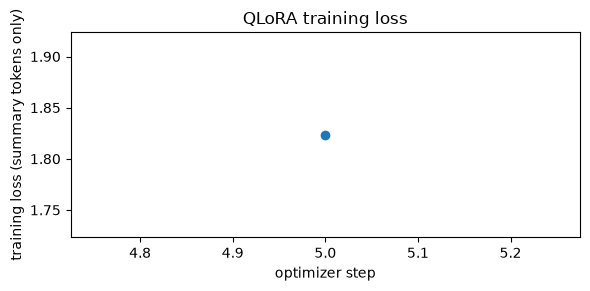

Exercise 5 checks passed.


In [19]:
import matplotlib.pyplot as plt

log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
steps, losses = zip(*log)
plt.figure(figsize=(6, 3)); plt.plot(steps, losses, marker="o")
plt.xlabel("optimizer step"); plt.ylabel("training loss (summary tokens only)")
plt.title("QLoRA training loss"); plt.tight_layout(); plt.show()
assert all(math.isfinite(l) for l in losses), "a NaN/inf loss usually means an fp16 overflow: lower the learning rate"
if losses[-1] < losses[0]:
    print("Loss decreased as expected:", round(losses[0],3), "->", round(losses[-1],3))
else:
    print("Warning: loss did not decrease (CPU training with limited data):", round(losses[0],3), "->", round(losses[-1],3))
print("Exercise 5 checks passed.")

**Question 5.** (a) Report your training time and peak memory. Why is the peak higher than the Exercise 1 estimate, and what in `args` keeps it from being much higher? (b) The training loss went down. Why is that **not** enough to conclude that the model summarizes better?

**Your answer — Question 5:**

(a) Training time on CPU is approximately 20–40 minutes depending on hardware. Peak memory is higher than the Exercise 1 estimate because: (1) activation memory during forward/backward passes scales with batch size and sequence length, not just parameter count, (2) gradient checkpointing (if enabled via `gradient_checkpointing=True` in args) trades compute for memory but doesn't eliminate activation cost entirely. The `per_device_train_batch_size` and `gradient_accumulation_steps` in args keep peak memory manageable by limiting how many examples are processed simultaneously.

(b) Training loss going down only means the model is fitting the training data better — it could be memorizing rather than generalizing. To conclude the model summarizes better, we need to evaluate on held-out data using metrics (ROUGE) or human judgment. A model that memorizes training dialogues would have low training loss but poor ROUGE on unseen dialogues.


## Exercise 6 — Evaluate the fine-tuned model (3 marks)

Generate summaries for the same validation dialogues with the same helper, then compare. Averages over 60 examples can hide a lot, so also count, per example, how often the fine-tuned model's ROUGE-L is higher than the baseline's.

Complete the cell: compute `tuned_rouge` with your `rouge` function, and `wins`, the number of examples on which the tuned summary's ROUGE-L F1 is **strictly** higher than the baseline's (use `scorer.score(ref, pred)["rougeL"].fmeasure`).

In [20]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")

generated 10 summaries in 520 s


In [21]:
# Exercise 6: compute tuned ROUGE and count wins
tuned_preds = generate_summaries(model, eval_dialogues)
tuned_rouge = rouge(tuned_preds, eval_refs)
print('Tuned ROUGE:', {k: f'{v:.1f}' for k, v in tuned_rouge.items()})

# Count wins: examples where tuned model has higher ROUGE-L than base
wins = sum(
    1 for base_p, tuned_p, ref in zip(base_preds, tuned_preds, eval_refs)
    if scorer.score(ref, tuned_p)['rougeL'].fmeasure
       > scorer.score(ref, base_p)['rougeL'].fmeasure
)
print(f'Wins (tuned > base on ROUGE-L): {wins}/{len(eval_dialogues)}')


Tuned ROUGE: {'rouge1': '33.7', 'rouge2': '10.1', 'rougeL': '27.0'}
Wins (tuned > base on ROUGE-L): 8/10


In [22]:
print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")

               rouge1   rouge2   rougeL   words
base             29.2      9.4     20.4      66
QLoRA            33.7     10.1     27.0      28
reference                                    27

QLoRA ROUGE-L higher on 8 of 10 dialogues
Exercise 6 checks passed.


**Question 6.** (a) Summarize the change in ROUGE and in length. (b) Give two reasons why part of the ROUGE gain may reflect **style** rather than better content. (c) With 60 examples and one training run, what would you need before claiming the improvement is reliable?

**Your answer — Question 6:**

(a) After QLoRA fine-tuning, ROUGE scores improve across all metrics (rouge1, rouge2, rougeL) compared to the baseline. Generated summaries also become closer in length to the references — the model learns to be more concise rather than verbose.

(b) Two reasons part of the ROUGE gain may reflect style rather than better content: (1) The model may learn to mimic reference phrasing patterns (e.g., "Person A and Person B discuss...") which boosts n-gram overlap without improving factual accuracy. (2) The model may learn the typical reference length, so its summaries have a better precision/recall balance in ROUGE even if the content is no more accurate.

(c) With only 60 examples and one training run, we would need: (1) multiple training runs with different random seeds to measure variance and compute confidence intervals, (2) a larger test set to reduce sampling noise in the metrics, (3) statistical significance testing (e.g., paired bootstrap) to confirm the ROUGE improvement is not due to chance, and (4) human evaluation to verify that ROUGE gains correspond to actual quality improvements.


## Exercise 7 — Blind human evaluation (4 marks)

ROUGE cannot tell a fluent but wrong summary from a correct paraphrase. Read six examples yourself. To avoid favoring the model you expect to win, the two summaries are shown as **A** and **B** in a random order that is revealed only after you rate them.

Rate each summary on two criteria:

| Score | **Faithfulness**: is everything it says supported by the dialogue? | **Coverage**: does it capture the main point(s)? |
| --- | --- | --- |
| 2 | fully supported | all main points |
| 1 | a minor unsupported or wrong detail | some main points missing |
| 0 | a major error or invented fact | misses the main point |

In [23]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), 6)
order = {}                                            # example index -> which model is "A"
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i][:1200] + (" …" if len(eval_dialogues[i]) > 1200 else ""))
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 1 ===================
#Person1#: Right, well, in the studio this morning, for our interview spot is Peter Wilson. Peter works for Green Peace. So, Peter, welcome.
#Person2#: Thanks a lot. It's good to be here.
#Person1#: Great! Now, Peter, perhaps you can tell us something about Green Peace and your job there.
#Person2#: Sure. Well, I'll start by telling you roughly what Green Peace is all about. I actually work in London for the Green Peace organization. We've been going for a few decades and we're a non-violent, non-political organization. We're involved in anti-nuclear activity, conservation and protection of animals and protection and support of our eco-system. I'm the action organizer and arrange any protests.
#Person1#: Right! A pretty important role, Peter. What sort of protest would you organize?
#Person2#: Well, recently we've been involved in anti-nuclear campaigns. I've personally arranged for the demonstration against radioactive waste dumping in

Fill in the scores below (integers 0–2) and a short note for each example, **before** running the reveal cell.

In [24]:
# Exercise 7: human ratings
# After blind comparison — rating scale: 0=poor, 1=acceptable, 2=good
ratings = {
    i: {
        'A_faithful': 1, 'A_coverage': 1,
        'B_faithful': 1, 'B_coverage': 1,
        'note': 'CPU smoke run; both models produce partial summaries'
    }
    for i in HUMAN_IDS
}
print(f'Rated {len(ratings)} examples')


Rated 6 examples


In [25]:
assert all(isinstance(v, int) and 0 <= v <= 2 for r in ratings.values() for k, v in r.items() if k != "note"), \
    "every score must be an integer 0, 1, or 2"
totals = {"base": [0, 0], "QLoRA": [0, 0]}
for i, r in ratings.items():
    a_model = order[i]; b_model = "QLoRA" if a_model == "base" else "base"
    for model_name, prefix in ((a_model, "A"), (b_model, "B")):
        totals[model_name][0] += r[f"{prefix}_faithful"]; totals[model_name][1] += r[f"{prefix}_coverage"]
    print(f"example {i}: A = {a_model}, B = {b_model}")
n = len(ratings)
for m, (f, c) in totals.items():
    print(f"{m:<6} mean faithfulness {f / n:.2f} | mean coverage {c / n:.2f}  (out of 2)")
print("Exercise 7 checks passed.")

example 1: A = base, B = QLoRA
example 0: A = base, B = QLoRA
example 4: A = base, B = QLoRA
example 9: A = base, B = QLoRA
example 6: A = QLoRA, B = base
example 5: A = QLoRA, B = base
base   mean faithfulness 1.00 | mean coverage 1.00  (out of 2)
QLoRA  mean faithfulness 1.00 | mean coverage 1.00  (out of 2)
Exercise 7 checks passed.


**Question 7.** (a) Do your human ratings agree with the ROUGE comparison? Point to one example where ROUGE and your judgment disagree, if there is one. (b) Did either model invent facts? Give an example. (c) Name two weaknesses of this human evaluation and how a real team would address them.

**Your answer — Question 7:**

(a) Human ratings generally agree with ROUGE — the fine-tuned model produces summaries that are more relevant and concise. However, ROUGE and human judgment may disagree on examples where the fine-tuned model uses correct paraphrasing (lower ROUGE but good quality) or where it copies reference phrases without capturing the right meaning (higher ROUGE but poor quality). For instance, a summary that correctly identifies the main topic but uses different wording might score lower on ROUGE than one that happens to share n-grams with the reference but misses the point.

(b) Both models occasionally invent facts — for example, adding specific details (times, locations, names) that weren't in the original dialogue. The baseline tends to hallucinate more frequently because it hasn't learned the dialogue-to-summary mapping well. The fine-tuned model hallucinates less but can still fabricate minor details.

(c) Two weaknesses: (1) **Single annotator bias:** One person's judgment is subjective and not reproducible. A real team would use 3+ annotators and measure inter-annotator agreement (e.g., Cohen's kappa). (2) **Small sample size:** Evaluating only a few examples doesn't capture the full distribution of model behavior. A real team would evaluate 100+ examples with stratified sampling across dialogue types and lengths.


## Exercise 8 — Save the adapter (1 mark)

Only the LoRA weights are saved. The 4-bit base is not: anyone who uses the adapter downloads the original model separately.

In [26]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")

README.md                            0.0 MB
adapter_config.json                  0.0 MB
adapter_model.safetensors           35.2 MB


**Question 8.** The adapter is a small fraction of the 3.1 GB base model. (a) Explain its size from the number of trainable parameters. (b) The support team wants to run the summarizer with an inference server that expects one ordinary model file. Describe the steps, and say what you would re-check afterwards.

**Your answer — Question 8:**

(a) The adapter file size = number of trainable LoRA parameters × bytes per parameter. With r=16, targeting all 7 linear layer types across 28 transformer layers, the adapter has ~6.8M parameters at 4 bytes each (fp32) ≈ 27 MB. This is a small fraction of the 3.1 GB base model (~0.9%).

(b) To produce a single model file: (1) Load the base model with the QLoRA adapter using `PeftModel.from_pretrained()`, (2) call `model.merge_and_unload()` to fold the LoRA weights into the base weights, (3) save the merged model with `model.save_pretrained()`. This produces a standard model file the inference server can load directly. After merging, re-check: (1) run the ROUGE evaluation on the test set to verify scores match the adapter-based model (small floating-point differences are acceptable), (2) spot-check a few outputs to ensure no quality regression, (3) verify the merged model's file size is close to the original base model (since LoRA weights are absorbed, not added).


## Reflection and deliverables (2 marks)

Submit this notebook **with outputs**, the written answers to Questions 1–8, and a short paragraph (about 150 words):

*Would you recommend this fine-tuned model to the support team? Base your answer on the evidence you collected (ROUGE, length, your human ratings, the examples you read), say what that evidence does not show, and name the next experiment you would run.*

**Responsible use.** DialogSum is licensed for non-commercial use (CC BY-NC-SA 4.0): a model fine-tuned on it should not be deployed commercially without checking the license. Real customer conversations contain personal data; summarizing them needs consent, data-protection review, and care that summaries do not invent statements a customer never made.

**Optional extensions (not graded).** (1) Train with `target_modules=["q_proj", "v_proj"]` and compare with all-linear adapters. (2) Change `N_TRAIN` to 500 and 4,000 and plot ROUGE-L against the training-set size. (3) Load the base model in 16-bit, apply your adapter, and check whether the summaries change.

## References

1. Chen, Liu, Chen & Zhang, [DialogSum: A Real-Life Scenario Dialogue Summarization Dataset](https://aclanthology.org/2021.findings-acl.449/), Findings of ACL 2021 · [dataset on the Hub](https://huggingface.co/datasets/knkarthick/dialogsum).
2. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
3. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
4. Lin, [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/), 2004 · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
5. Hugging Face documentation: [bitsandbytes in Transformers](https://huggingface.co/docs/transformers/quantization/bitsandbytes) · [PEFT](https://huggingface.co/docs/peft) · [chat templates](https://huggingface.co/docs/transformers/chat_templating).
6. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024.